<a href="https://colab.research.google.com/github/naifahamanda/Studi_Kasus_Informatics_Practitioner_Lecture_Series_2026/blob/main/studi_kasus_dan_implementasi_materi_2_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Prediksi dan Preskripsi Churn Pelanggan (Customer Churn Analytics)**

# **Studi Kasus:**
Prediksi dan Preskripsi Churn Pelanggan (Customer Churn Analytics)
# **Latar Belakang Masalah:**
Sebuah perusahaan penyedia layanan/layanan berlangganan menghadapi masalah tingginya tingkat pembatalan layanan oleh pelanggan (customer churn). Manajemen ingin memahami faktor apa saja yang menyebabkan pelanggan berhenti berlangganan (Diagnostic Analytics), memprediksi pelanggan mana yang berisiko tinggi akan churn (Predictive Analytics), serta mendapatkan saran tindakan retensi yang personal untuk pelanggan tersebut (Prescriptive Analytics menggunakan AI).

# **Metodologi (CRISP-DM)**

1. Business Understanding: Mengurangi churn pelanggan dan meningkatkan retensi.

2. Data Understanding & Preparation: Mengelola messy data (data hilang, entri ganda, tipe data yang salah).

3. Exploratory Data Analysis (EDA) & Descriptive/Diagnostic Analytics: Mengidentifikasi pola dan faktor pendorong churn.

4. Modeling & Evaluation (Predictive Analytics): Membangun model Machine Learning untuk memprediksi churn.

5. Prescriptive Analytics & Generative AI: Menggunakan model AI / LLM untuk memberikan rekomendasi tindakan konkret bagi pelanggan berisiko.

In [ ]:
# Install library yang dibutuhkan
!pip install -q pandas numpy matplotlib seaborn scikit-learn google-genai

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Pengaturan visualisasi
sns.set_theme(style="whitegrid")
print("✅ Library berhasil dimuat!")

✅ Library berhasil dimuat!


In [ ]:
np.random.seed(42)
n_samples = 1000

data = {
    'CustomerID': [f'CUST-{1000+i}' for i in range(n_samples)],
    'Tenure_Months': np.random.randint(1, 60, size=n_samples),
    'Monthly_Charges': np.random.uniform(20.0, 120.0, size=n_samples),
    'Total_Charges': np.random.uniform(100.0, 5000.0, size=n_samples),
    'Contract_Type': np.random.choice(['Month-to-Month', 'One Year', 'Two Year'], size=n_samples, p=[0.6, 0.25, 0.15]),
    'Tech_Support': np.random.choice(['Yes', 'No'], size=n_samples, p=[0.4, 0.6]),
    'Churn': np.random.choice([0, 1], size=n_samples, p=[0.7, 0.3])
}

df_raw = pd.DataFrame(data)

# Introduksi "Messy Data"
# 1. Missing Values
df_raw.loc[np.random.choice(df_raw.index, 30), 'Total_Charges'] = np.nan
df_raw.loc[np.random.choice(df_raw.index, 20), 'Contract_Type'] = np.nan

# 2. Duplicate Rows
df_raw = pd.concat([df_raw, df_raw.iloc[:15]], ignore_index=True)

print(f"Bentuk Dataset Awal (Messy Data): {df_raw.shape}")
df_raw.head()

Bentuk Dataset Awal (Messy Data): (1015, 7)


,CustomerID,Tenure_Months,Monthly_Charges,Total_Charges,Contract_Type,Tech_Support,Churn
0,CUST-1000,39,62.053578,1867.785344,One Year,No,1
1,CUST-1001,52,98.466826,4538.866413,Month-to-Month,No,0
2,CUST-1002,29,83.936136,NaN,One Year,No,1
3,CUST-1003,15,100.504467,2827.521584,Month-to-Month,Yes,0
4,CUST-1004,43,110.315106,1352.660489,Month-to-Month,No,0


In [ ]:
def clean_data(data_frame):
    df = data_frame.copy()

    # 1. Hapus Duplikat
    initial_rows = len(df)
    df = df.drop_duplicates()
    print(f"🗑️ Menghapus {initial_rows - len(df)} baris duplikat.")

    # 2. Penanganan Missing Values (Imputasi)
    # Total_Charges diisi dengan nilai median berdasarkan Tenure
    df['Total_Charges'] = df['Total_Charges'].fillna(df['Total_Charges'].median())

    # Contract_Type diisi dengan modus
    df['Contract_Type'] = df['Contract_Type'].fillna(df['Contract_Type'].mode()[0])

    print("✅ Pengecekan Missing Values Setelah Cleaning:")
    print(df.isnull().sum()[df.isnull().sum() > 0])

    return df

df_clean = clean_data(df_raw)

🗑️ Menghapus 15 baris duplikat.
✅ Pengecekan Missing Values Setelah Cleaning:
Series([], dtype: int64)


/tmp/ipykernel_2292/745899283.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='Churn', ax=axes[0], palette='Set2')
/tmp/ipykernel_2292/745899283.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Churn', y='Tenure_Months', ax=axes[2], palette='mako')


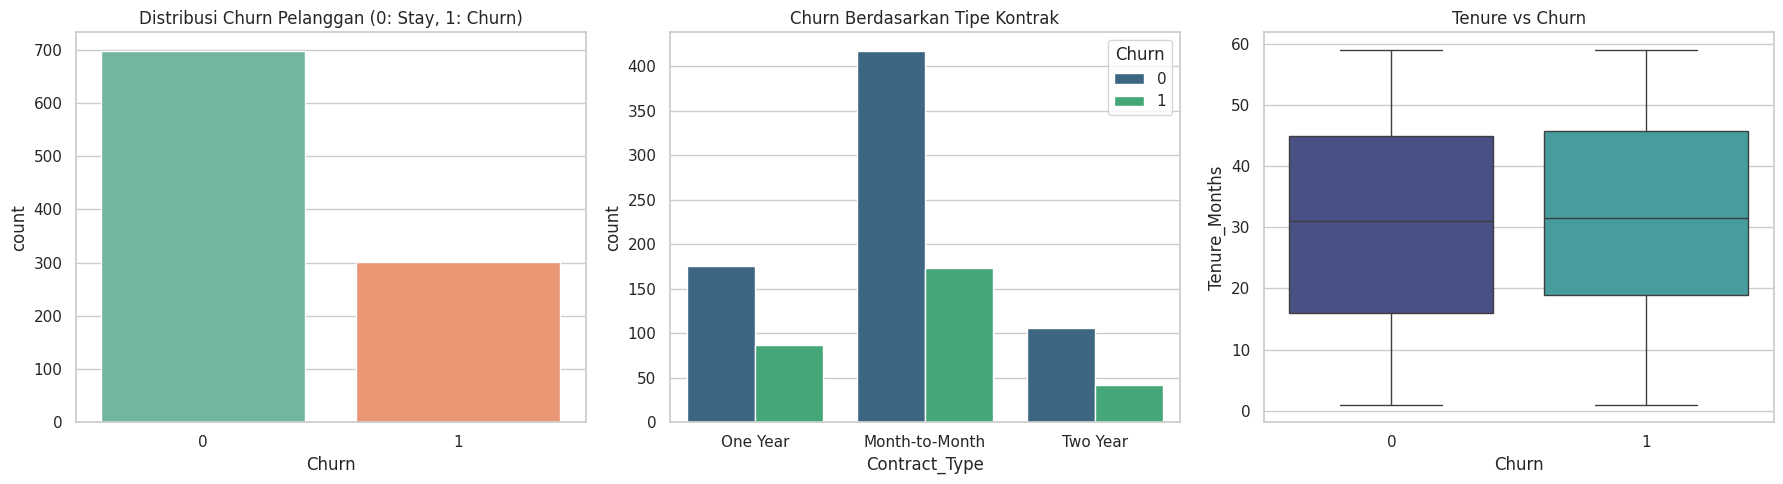

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribusi Churn (Descriptive)
sns.countplot(data=df_clean, x='Churn', ax=axes[0], palette='Set2')
axes[0].set_title('Distribusi Churn Pelanggan (0: Stay, 1: Churn)')

# 2. Hubungan Tipe Kontrak dengan Churn (Diagnostic)
sns.countplot(data=df_clean, x='Contract_Type', hue='Churn', ax=axes[1], palette='viridis')
axes[1].set_title('Churn Berdasarkan Tipe Kontrak')

# 3. Hubungan Masa Berlangganan (Tenure) dengan Churn (Diagnostic)
sns.boxplot(data=df_clean, x='Churn', y='Tenure_Months', ax=axes[2], palette='mako')
axes[2].set_title('Tenure vs Churn')

plt.tight_layout()
plt.show()

In [ ]:
# Feature Encoding
df_model = df_clean.drop(columns=['CustomerID'])
label_encoders = {}

for col in ['Contract_Type', 'Tech_Support']:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    label_encoders[col] = le

# Split Dataset
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# Evaluation
y_pred = rf_model.predict(X_test_scaled)
y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print("📊 --- Evaluasi Model Predictive Analytics ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

📊 --- Evaluasi Model Predictive Analytics ---
              precision    recall  f1-score   support

           0       0.69      0.84      0.76       140
           1       0.27      0.13      0.18        60

    accuracy                           0.63       200
   macro avg       0.48      0.49      0.47       200
weighted avg       0.57      0.63      0.59       200

ROC-AUC Score: 0.5053


In [ ]:
import pandas as pd

def generate_prescriptive_recommendation_local(customer_data, churn_risk_prob):
    """
    Menghasilkan analisis dan rekomendasi preskriptif secara lokal (Rule-Based)
    tanpa menggunakan API eksternal.
    """
    recommendations = []
    analysis = []

    # 1. Analisis Faktor Risiko
    if churn_risk_prob >= 0.5:
        risk_level = "Sangat Tinggi (HIGH)"
    elif churn_risk_prob >= 0.3:
        risk_level = "Sedang (MEDIUM)"
    else:
        risk_level = "Rendah (LOW)"

    analysis.append(f"Pelanggan memiliki tingkat risiko churn **{risk_level}** ({churn_risk_prob * 100:.1f}%).")

    # Evaluasi Tipe Kontrak
    if customer_data['Contract_Type'] == 'Month-to-Month':
        analysis.append("- Menggunakan kontrak bulanan (Month-to-Month) yang sangat fleksibel untuk dibatalkan kapan saja.")
        recommendations.append("Tawarkan diskon khusus sebesar 15-20% jika pelanggan bersedia beralih ke kontrak tahunan (Annual Contract).")

    # Evaluasi Layanan Tech Support
    if customer_data['Tech_Support'] == 'No':
        analysis.append("- Tidak memiliki layanan Tech Support, yang meningkatkan potensi frustrasi saat terjadi kendala teknis.")
        recommendations.append("Berikan uji coba gratis layanan Tech Support premium selama 3 bulan.")

    # Evaluasi Biaya Bulanan & Tenure
    if customer_data['Monthly_Charges'] > 70:
        analysis.append(f"- Tagihan bulanan tergolong tinggi (${customer_data['Monthly_Charges']:.2f}).")
        recommendations.append("Lakukan audit paket langganan dan tawarkan penyesuaian bundle layanan yang lebih hemat biaya.")

    if customer_data['Tenure_Months'] < 12:
        analysis.append(f"- Pelanggan masih tergolong baru (Tenure: {customer_data['Tenure_Months']} bulan).")
        recommendations.append("Kirimkan program onboarding/edukasi fitur dan voucher apresiasi pelanggan baru.")

    if not recommendations:
        recommendations.append("Kirimkan survei kepuasan berkala dan pertahankan kualitas layanan saat ini.")

    # Format Output
    output_text = f"### 📊 Analisis Risiko Churn\n" + "\n".join(analysis) + "\n\n"
    output_text += "### 💡 3 Rekomendasi Tindakan Preskriptif (Prescriptive Actions):\n"
    for i, rec in enumerate(recommendations[:3], 1):
        output_text += f"{i}. {rec}\n"

    return output_text

# -------------------------------------------------------------------
# Pengambilan Sampel & Penanganan Warning StandardScaler
# -------------------------------------------------------------------
sample_idx = 0
sample_customer = df_clean.iloc[sample_idx]

# Gunakan DataFrame 1 baris untuk menjaga nama kolom (mencegah UserWarning)
sample_features_df = pd.DataFrame([X_test.iloc[sample_idx]], columns=X_test.columns)
sample_features_scaled = scaler.transform(sample_features_df)

# Prediksi Probabilitas Churn menggunakan Model Machine Learning
sample_churn_prob = rf_model.predict_proba(sample_features_scaled)[0][1]

print(f"ID Pelanggan: {sample_customer['CustomerID']}")
print(f"Probabilitas Churn (ML Prediction): {sample_churn_prob * 100:.2f}%\n")

# Eksekusi Fungsi Preskriptif Lokal
recommendation_result = generate_prescriptive_recommendation_local(sample_customer, sample_churn_prob)
print("🤖 --- Hasil Analisis & Rekomendasi Preskriptif (Local Rule-Based) ---")
print(recommendation_result)

ID Pelanggan: CUST-1000
Probabilitas Churn (ML Prediction): 45.00%

🤖 --- Hasil Analisis & Rekomendasi Preskriptif (Local Rule-Based) ---
### 📊 Analisis Risiko Churn
Pelanggan memiliki tingkat risiko churn **Sedang (MEDIUM)** (45.0%).
- Tidak memiliki layanan Tech Support, yang meningkatkan potensi frustrasi saat terjadi kendala teknis.

### 💡 3 Rekomendasi Tindakan Preskriptif (Prescriptive Actions):
1. Berikan uji coba gratis layanan Tech Support premium selama 3 bulan.

